# Do SFT Core stories look less like RL Core stories than DPO's do?

**Question.** 44.4% of Instruct-SFT stories and 53.4% of Instruct-DPO stories are Core (notebook 01). Is a Core
story just a Core story at every stage, or do SFT's Core stories *read* differently, with DPO's closer to what the
final RL Think model writes? We train text classifiers to tell each stage's Core stories apart from RL's.
**The harder it is to tell them apart, the more alike they are.**

**Data**

| Stage | File | Stories | Setup |
|---|---|---|---|
| SFT | `new_stories/data/instruct-sft.jsonl` | 500 | Instruct branch, 5 prompts × 100, "~500 words" system prompt, T 0.6 |
| DPO | `new_stories/data/instruct-dpo.jsonl` | 500 | same as SFT |
| RL | `generated_stories/data/…Olmo-3-7B-Think…jsonl` | 5,000 | **Think** branch final (RLVR), 1 prompt, old system prompt, old settings |

**⚠ Main confound.** SFT and DPO are *Instruct* checkpoints run with our setup. RL is the *Think* model from the old
run. "Looks different from RL" therefore mixes **training stage** with **branch, prompt and run setup**. The
controls in §2 remove the obvious shortcuts (length, markdown, names, the Core words themselves), but what remains
can't be pinned on any one cause. The SFT-vs-RL vs DPO-vs-RL *comparison* is fairer than either number alone,
because SFT and DPO share the same setup, so the confound is about the same size in both.

**Design (chosen 2026-11-10)**
1. **Pairwise classifiers:** SFT-vs-RL and DPO-vs-RL, cross-validated ROC AUC (0.5 = indistinguishable,
   1.0 = perfectly separable). Classes balanced, RL subsampled, repeated over many random draws.
2. **Projection:** train on SFT-vs-RL, then score DPO stories the model never saw. Where does DPO fall between
   SFT (0) and RL (1)?
3. **Features:** word 1-2 gram TF-IDF + logistic regression, with Core words and proper names masked.
4. **Control:** repeat everything on **non-Core** stories. If non-Core stories show the same shift, the change
   isn't specific to Core stories.

Only the story text is used, never the prompt or reasoning (the Instruct models produce no reasoning; the old Think
run already had `<think>` removed).

## 0. Setup

Run from the project root (scikit-learn is pulled in by `uv`, nothing is installed globally):

```bash
uv run --no-project --with jupyterlab,pandas,scikit-learn,matplotlib jupyter lab
```

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd()
while not (ROOT / "helper_scripts" / "core_rates.py").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the project folder.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "helper_scripts"))
from core_rates import CORE, PATTERN, score_core  # noqa: E402  (the paper's verified scorer)

# ---- Analysis settings ------------------------------------------------------
N_WORDS = 250   # every story is cut to its first N_WORDS words; shorter stories are dropped
N_DRAWS = 30    # random balanced draws per comparison (RL subsampled, CV folds reshuffled)
N_FOLDS = 5
SEED = 20261110
STAGES = ["SFT", "DPO", "RL"]
COLORS = {"SFT": "#2a78d6", "DPO": "#eb6834", "RL": "#1baf7a"}  # validated categorical slots 1-3

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)
print("Project root:", ROOT)

Project root: /Users/mihirjoshi/AI Research - Cornell


## 1. Load the stories and label Core vs non-Core

Core is decided on the **full** story with the paper's scorer (≥1 of the 11 Core words), so the Core shares match
notebook 01 (SFT 44.4%, DPO 53.4%) and Table 5 (RL 73.1%).

In [2]:
OLD_RL = ROOT / "generated_stories" / "data" / "20260520_183858_local-Olmo-3-7B-Think_write_a_story.jsonl"
NEW = ROOT / "new_stories" / "data"

frames = []
for stage, path, field in [("SFT", NEW / "instruct-sft.jsonl", "story"),
                           ("DPO", NEW / "instruct-dpo.jsonl", "story"),
                           ("RL", OLD_RL, "content")]:
    d = pd.read_json(path, lines=True)
    frames.append(pd.DataFrame({"stage": stage, "raw": d[field].astype(str),
                                "prompt": d["prompt"] if "prompt" in d else "write a story (old run)"}))
df = pd.concat(frames, ignore_index=True)
assert not df["raw"].str.contains("<think>|</think>").any(), "reasoning leaked into a story"

df["core"] = df["raw"].map(lambda t: score_core(t)["has_core"])
df["words_full"] = df["raw"].str.split().str.len()

(df.groupby("stage", sort=False)
   .agg(stories=("core", "size"), core_stories=("core", "sum"), core_pct=("core", "mean"),
        median_words=("words_full", "median"))
   .assign(core_pct=lambda t: (100 * t["core_pct"]).round(1)))

,stories,core_stories,core_pct,median_words
stage,,,,
SFT,500,222,44.4,524.0
DPO,500,267,53.4,604.0
RL,5000,3653,73.1,428.0


## 2. Remove shortcuts the classifier could use instead of story content

Every change here removes a difference that comes from **how the runs were set up**, not from what the model writes:

| Shortcut | Evidence | Control |
|---|---|---|
| Length | RL median ≈ 430 words, SFT ≈ 520, DPO ≈ 600 (the "~500 words" line) | keep only the first `N_WORDS` = 250 words; drop shorter stories |
| Markdown/whitespace | 90% of RL stories use `*italics*` and double-space line breaks vs ~20% of Instruct | strip `*` `_` `#`, unify quotes, collapse whitespace |
| The Core words | DPO uses *lighthouse* 2× as often as SFT; trivially separable | Core professions + *lighthouse* → `xcore`, and **no feature may contain `xcore`** |
| Names and places | *Clara* (DPO), *Willowbrook* (SFT), *Marrow's End* (DPO) are run-specific favourites | any word capitalized in ≥ 90% of its corpus uses → `xname` (Core names *Elara/Mara/Elias* included, so having a Core name isn't visible either) |

Ending tells (e.g. "The End") are mostly cut off by truncation. §6 checks how much each control matters.

In [3]:
WORD = re.compile(r"[A-Za-z]+")
CORE_NAMES = re.compile(r"\b(?:" + "|".join(CORE["names"]) + r")\b", re.IGNORECASE)
CORE_OTHER = re.compile(r"\b(?:" + "|".join(CORE["professions"] + CORE["locations"]) + r")\b", re.IGNORECASE)


def normalize(text: str) -> str:
    # Remove formatting differences between runs (markdown, quote style, whitespace).
    t = re.sub(r"[*_#]+", " ", text)
    t = re.sub(r"[“”]", '"', t)
    t = re.sub(r"[‘’]", "'", t)
    return re.sub(r"\s+", " ", t).strip()


def first_words(text: str, n: int = N_WORDS) -> str:
    return " ".join(text.split()[:n])


df["norm"] = df["raw"].map(normalize)
df["n_words"] = df["norm"].str.split().str.len()
df["trunc"] = df["norm"].map(first_words)

# A word is treated as a proper noun if it is capitalized in at least 90% of its uses across the whole corpus.
# (A plain "never lower-case" rule leaks: "clara", "lila" and "marrow" each occur lower-case a few times.)
from collections import Counter

lower_n, cap_n = Counter(), Counter()
for t in df["norm"]:
    for w in WORD.findall(t):
        if w.islower():
            lower_n[w] += 1
        elif w[0].isupper() and not w.isupper():
            cap_n[w.lower()] += 1
PROPER = {w for w, c in cap_n.items() if len(w) > 1 and lower_n[w] < 0.1 * (c + lower_n[w])}


def mask(text: str) -> str:
    t = CORE_NAMES.sub("xname", text)
    t = CORE_OTHER.sub("xcore", t)
    return WORD.sub(lambda m: "xname" if m.group().lower() in PROPER and not m.group().islower() else m.group(), t)


df["text"] = df["trunc"].map(mask)
df["kept"] = df["n_words"] >= N_WORDS
print(f"{len(PROPER):,} words treated as proper nouns, e.g.:", ", ".join(
    [w for w in sorted(PROPER, key=lambda w: -cap_n[w])[:25]]))

ex = df[(df["stage"] == "DPO") & df["core"] & df["kept"]].iloc[0]
print("BEFORE:", ex["raw"][:400].replace("\n", " "), "…\n")
print("AFTER: ", ex["text"][:400], "…\n")
print(f"Dropped as shorter than {N_WORDS} words:")
df.groupby(["stage", "core"], sort=False)["kept"].agg(kept="sum", dropped=lambda k: (~k).sum())

1,255 words treated as proper nouns, e.g.: elara, lila, clara, elias, kael, eli, lira, mira, eleanor, mr, maya, mrs, marrow, voss, blackthorn, mara, silas, maris, willowbrook, october, alex, eliza, thorne, lily, harlow
BEFORE: The first time Mara saw the fox was on a rain-soaked afternoon, halfway between dusk and nightfall. She was walking home from the bakery, the air heavy with the scent of wet earth and distant thunder. Her boots squelched through puddles, the cobblestones gleaming beneath her. She wore a faded blue scarf knotted haphazardly at her neck, because today she felt like a wanderer rather than a girl with …

AFTER:  The first time xname saw the fox was on a rain-soaked afternoon, halfway between dusk and nightfall. She was walking home from the bakery, the air heavy with the scent of wet earth and distant thunder. Her boots squelched through puddles, the cobblestones gleaming beneath her. She wore a faded blue scarf knotted haphazardly at her neck, because today she felt

kept  dropped
stage core                
SFT   True    222        0
      False   275        3
DPO   True    267        0
      False   233        0
RL    False  1225      122
      True   3539      114

## 3. The classifier and the evaluation loop

- **Model:** TF-IDF on word unigrams + bigrams (sublinear tf, `min_df=3`), any n-gram containing `xcore` removed,
  then L2 logistic regression. Linear and interpretable: the weights in §5 show *what* differs.
- **Balanced classes:** for each comparison both groups are subsampled to the same `n`. Within Core and within
  non-Core, **every comparison uses the same `n`** (the smallest group), so AUCs are comparable across pairs.
- **Uncertainty:** `N_DRAWS` random draws × stratified 5-fold CV. We report the mean AUC and the 2.5–97.5%
  range across draws. That range covers subsampling and fold noise, *not* the fact that only one set of 500 stories
  per checkpoint exists, so treat it as a lower bound on the real uncertainty.
- **Null baseline:** RL vs RL (two disjoint random halves of RL) should give AUC ≈ 0.5. If not, the pipeline leaks.

In [4]:
_base_analyzer = CountVectorizer(ngram_range=(1, 2), lowercase=True).build_analyzer()


def analyzer(doc: str) -> list[str]:
    return [g for g in _base_analyzer(doc) if "xcore" not in g]


def make_model(analyzer=analyzer):
    return make_pipeline(TfidfVectorizer(analyzer=analyzer, min_df=3, sublinear_tf=True),
                         LogisticRegression(C=1.0, max_iter=5000))


def pool(stage: str, core: bool, col: str = "text", require_kept: bool = True) -> np.ndarray:
    m = (df["stage"] == stage) & (df["core"] == core)
    if require_kept:
        m &= df["kept"]
    return df.loc[m, col].to_numpy()


def cv_auc(a: np.ndarray, b: np.ndarray, n: int, rng, col_model=make_model, score_c: np.ndarray | None = None):
    # One balanced draw: n from a (label 0) vs n from b (label 1). Returns AUC, accuracy, and out-of-fold
    # P(label 1) for a and b, plus fold-averaged P(label 1) for every text in score_c (never trained on).
    ia = rng.choice(len(a), n, replace=False)
    ib = rng.choice(len(b), n, replace=False)
    X = np.concatenate([a[ia], b[ib]])
    y = np.r_[np.zeros(n), np.ones(n)]
    oof = np.zeros(len(X))
    pc = np.zeros(len(score_c)) if score_c is not None else None
    skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=int(rng.integers(1 << 31)))
    for tr, te in skf.split(X, y):
        m = col_model().fit(X[tr], y[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
        if pc is not None:
            pc += m.predict_proba(score_c)[:, 1] / N_FOLDS
    return roc_auc_score(y, oof), accuracy_score(y, oof > 0.5), (ia, oof[:n]), (ib, oof[n:]), pc


def summarize(vals) -> str:
    v = np.asarray(vals)
    return f"{v.mean():.3f}  [{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"

## 4. Pairwise separability: how easily can a classifier tell each stage from RL?

Read the **Core** rows first. If DPO's Core stories became more RL-like than SFT's, the DPO-vs-RL AUC is clearly
*below* the SFT-vs-RL AUC. SFT-vs-DPO says how different the two Instruct stages are from each other. The
**non-Core** rows are the control.

If both stage-vs-RL AUCs sit at ≈ 1.0, the classifier separates *every* Instruct story from the old Think run
(the branch/setup confound) and AUC can't rank the stages. §5 (projection) and §6 (learning curve) still can.

In [5]:
rng = np.random.default_rng(SEED)
PAIRS = [("SFT", "RL"), ("DPO", "RL"), ("SFT", "DPO"), ("RL", "RL")]
results, auc_draws = [], {}
for core in (True, False):
    pools = {s: pool(s, core) for s in STAGES}
    n = min(len(pools["SFT"]), len(pools["DPO"]))
    for a, b in PAIRS:
        aucs, accs = [], []
        for _ in range(N_DRAWS):
            if a == b:  # null: two disjoint random halves of the same stage
                perm = rng.permutation(pools[a])
                auc, acc, *_ = cv_auc(perm[:n], perm[n:2 * n], n, rng)
            else:
                auc, acc, *_ = cv_auc(pools[a], pools[b], n, rng)
            aucs.append(auc)
            accs.append(acc)
        label = "Core" if core else "non-Core"
        auc_draws[(label, f"{a} vs {b}")] = aucs
        results.append({"stories": label, "comparison": f"{a} vs {b}" + ("  (null)" if a == b else ""),
                        "n per side": n, "AUC mean [95% range]": summarize(aucs),
                        "accuracy": summarize(accs)})
auc_table = pd.DataFrame(results).set_index(["stories", "comparison"])
auc_table

n per side   AUC mean [95% range]               accuracy
stories  comparison                                                                
Core     SFT vs RL                222  1.000  [1.000, 1.000]  0.997  [0.993, 1.000]
         DPO vs RL                222  1.000  [1.000, 1.000]  0.997  [0.991, 1.000]
         SFT vs DPO               222  0.867  [0.858, 0.876]  0.776  [0.761, 0.792]
         RL vs RL  (null)         222  0.503  [0.411, 0.557]  0.509  [0.425, 0.557]
non-Core SFT vs RL                233  1.000  [0.999, 1.000]  0.993  [0.987, 0.998]
         DPO vs RL                233  1.000  [0.999, 1.000]  0.994  [0.988, 1.000]
         SFT vs DPO               233  0.868  [0.852, 0.880]  0.775  [0.759, 0.792]
         RL vs RL  (null)         233  0.492  [0.428, 0.559]  0.494  [0.437, 0.547]

In [6]:
# Paired difference within the same draw index isn't meaningful (draws are independent), so compare the
# distributions: share of draws where SFT-vs-RL AUC exceeds DPO-vs-RL AUC, over all draw pairs.
diff_rows = []
for label in ("Core", "non-Core"):
    s, d = np.array(auc_draws[(label, "SFT vs RL")]), np.array(auc_draws[(label, "DPO vs RL")])
    diff_rows.append({"stories": label, "SFT-vs-RL minus DPO-vs-RL (mean AUC)": round(s.mean() - d.mean(), 3),
                      "P(SFT-vs-RL AUC > DPO-vs-RL AUC)": round((s[:, None] > d[None, :]).mean(), 3)})
pd.DataFrame(diff_rows).set_index("stories")

,SFT-vs-RL minus DPO-vs-RL (mean AUC),P(SFT-vs-RL AUC > DPO-vs-RL AUC)
stories,,
Core,-0.0,0.302
non-Core,0.0,0.593


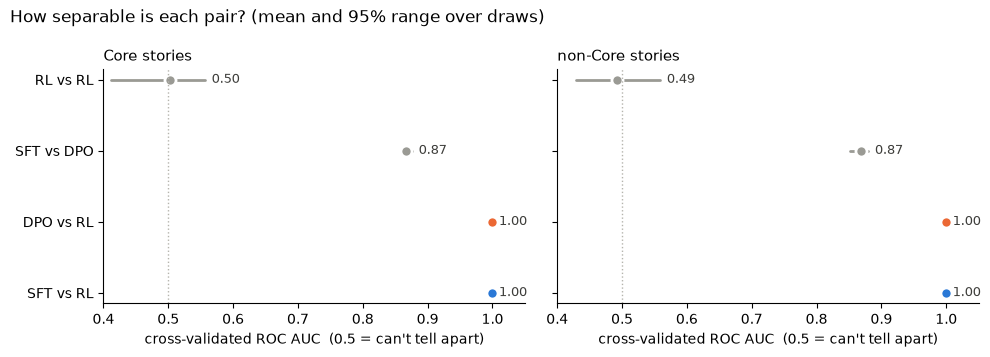

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True, sharey=True)
order = ["SFT vs RL", "DPO vs RL", "SFT vs DPO", "RL vs RL"]
for ax, label in zip(axes, ("Core", "non-Core")):
    for i, comp in enumerate(order):
        v = np.array(auc_draws[(label, comp)])
        color = {"SFT vs RL": COLORS["SFT"], "DPO vs RL": COLORS["DPO"]}.get(comp, "#9a9a94")
        ax.plot([np.percentile(v, 2.5), np.percentile(v, 97.5)], [i, i], color=color, lw=2, solid_capstyle="round")
        ax.plot(v.mean(), i, "o", ms=8, color=color, mec="white", mew=2)
        ax.text(np.percentile(v, 97.5) + 0.01, i, f"{v.mean():.2f}", va="center", fontsize=9, color="#3d3d3a")
    ax.axvline(0.5, color="#b5b4ad", lw=1, ls=":")
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.set_title(f"{label} stories", loc="left", fontsize=11)
    ax.set_xlabel("cross-validated ROC AUC  (0.5 = can't tell apart)")
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_xlim(0.4, 1.05)
fig.suptitle("How separable is each pair? (mean and 95% range over draws)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

## 5. Projection: where do DPO stories sit on the SFT → RL axis?

Train SFT-vs-RL (label 1 = RL), then score DPO stories the model has never seen. SFT and RL get out-of-fold scores,
DPO gets the average over fold models. Each story's score is averaged over all draws. The **position** of DPO is

$$\text{position} = \frac{\overline{P}(\text{RL}\mid \text{DPO}) - \overline{P}(\text{RL}\mid \text{SFT})}{\overline{P}(\text{RL}\mid \text{RL}) - \overline{P}(\text{RL}\mid \text{SFT})}$$

0 = DPO looks exactly like SFT on this axis, 1 = exactly like RL, < 0 = moved *away* from RL. This asks
specifically whether DPO moved in **RL's direction**, which a plain DPO-vs-RL AUC can't separate from moving
sideways.

For the projection, DPO uses **all** its kept stories of that type (no subsampling), since it's never trained on.
The CI is a **story-level bootstrap** (resample stories within each stage), which covers the fact that we have
only one sample of stories per checkpoint. The last line tests whether DPO moved further toward RL on Core
stories than on non-Core stories.

In [8]:
def project(a: str, b: str, c: str, core: bool, draws: int = N_DRAWS, col: str = "text",
            need_kept: bool = True, model=make_model, seed: int = SEED + 1):
    # Train a-vs-b (label 1 = b) over many balanced draws, score c (never trained on).
    # Returns each story's score averaged over the draws it was scored in, per stage.
    rng = np.random.default_rng(seed)
    pools = {s: pool(s, core, col, need_kept) for s in (a, b, c)}
    n = min(len(pool("SFT", core, col, need_kept)), len(pool("DPO", core, col, need_kept)))
    tot = {s: np.zeros(len(p)) for s, p in pools.items()}
    cnt = {s: np.zeros(len(p)) for s, p in pools.items()}
    for _ in range(draws):
        _, _, (ia, pa), (ib, pb), pc = cv_auc(pools[a], pools[b], n, rng, col_model=model, score_c=pools[c])
        for s, idx, p in ((a, ia, pa), (b, ib, pb), (c, np.arange(len(pools[c])), pc)):
            np.add.at(tot[s], idx, p)
            np.add.at(cnt[s], idx, 1)
    return {s: tot[s][cnt[s] > 0] / cnt[s][cnt[s] > 0] for s in pools}


def position(sc: dict, a: str, b: str, c: str) -> float:
    return (sc[c].mean() - sc[a].mean()) / (sc[b].mean() - sc[a].mean())


def boot_position(sc: dict, a: str, b: str, c: str, reps: int = 2000, seed: int = SEED) -> np.ndarray:
    # Resample stories within each stage: uncertainty from having only this one sample of stories.
    rng = np.random.default_rng(seed)
    out = np.empty(reps)
    for r in range(reps):
        res = {s: rng.choice(v, len(v)) for s, v in sc.items()}
        out[r] = position(res, a, b, c)
    return out


proj_scores, boots, proj_rows = {}, {}, []
for core in (True, False):
    label = "Core" if core else "non-Core"
    sc = proj_scores[label] = project("SFT", "RL", "DPO", core)
    bt = boots[label] = boot_position(sc, "SFT", "RL", "DPO")
    proj_rows.append({"stories": label, **{f"mean P(RL) | {s}": round(sc[s].mean(), 3) for s in STAGES},
                      "DPO position (0=SFT, 1=RL)": round(position(sc, "SFT", "RL", "DPO"), 3),
                      "95% bootstrap CI": f"[{np.percentile(bt, 2.5):.3f}, {np.percentile(bt, 97.5):.3f}]",
                      "share of DPO stories with P(RL) > 0.5": f"{100 * (sc['DPO'] > 0.5).mean():.1f}%"})
display(pd.DataFrame(proj_rows).set_index("stories").T)

d = boots["Core"] - boots["non-Core"]
print(f"Core minus non-Core position: {position(proj_scores['Core'], 'SFT', 'RL', 'DPO') - position(proj_scores['non-Core'], 'SFT', 'RL', 'DPO'):.3f}"
      f"  (95% CI [{np.percentile(d, 2.5):.3f}, {np.percentile(d, 97.5):.3f}], share of bootstrap reps ≤ 0: {(d <= 0).mean():.3f})")

stories,Core,non-Core
mean P(RL) | SFT,0.276,0.269
mean P(RL) | DPO,0.332,0.306
mean P(RL) | RL,0.722,0.73
"DPO position (0=SFT, 1=RL)",0.126,0.08
95% bootstrap CI,"[0.103, 0.149]","[0.057, 0.104]"
share of DPO stories with P(RL) > 0.5,0.4%,0.4%


Core minus non-Core position: 0.046  (95% CI [0.014, 0.079], share of bootstrap reps ≤ 0: 0.005)


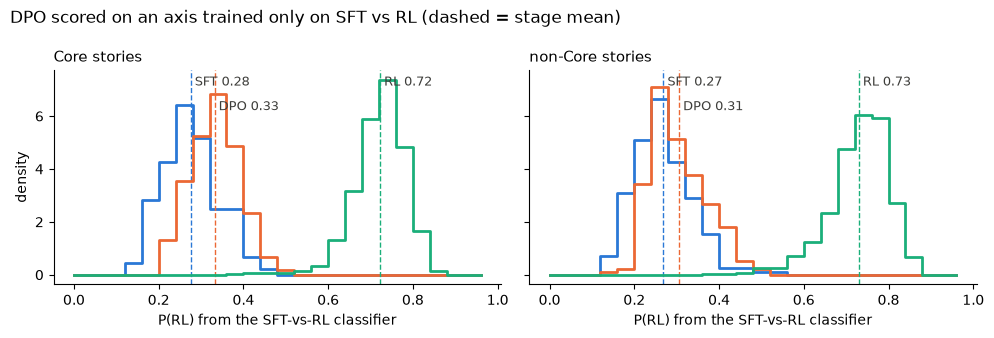

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
bins = np.linspace(0, 1, 26)
for ax, label in zip(axes, ("Core", "non-Core")):
    for s in STAGES:
        p = proj_scores[label][s]
        h, _ = np.histogram(p, bins=bins, density=True)
        ax.step(bins[:-1], h, where="post", color=COLORS[s], lw=2)
        ax.axvline(p.mean(), color=COLORS[s], lw=1, ls="--")
    ymax = ax.get_ylim()[1]
    for s, frac in zip(STAGES, (0.97, 0.85, 0.97)):  # stagger SFT/DPO labels, their means are close
        ax.text(proj_scores[label][s].mean(), ymax * frac, f" {s} {proj_scores[label][s].mean():.2f}",
                color="#3d3d3a", fontsize=9, va="top")
    ax.set_title(f"{label} stories", loc="left", fontsize=11)
    ax.set_xlabel("P(RL) from the SFT-vs-RL classifier")
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel("density")
fig.suptitle("DPO scored on an axis trained only on SFT vs RL (dashed = stage mean)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

## 6. Learning curve: how few examples does each separation need?

When full-data AUC saturates, a pair that is *more alike* still needs **more training examples** before the
classifier can separate it. Train on `k` stories per side, test on a fixed held-out set of 60 per side.

stories      Core            non-Core          
pair    DPO vs RL SFT vs RL DPO vs RL SFT vs RL
k                                              
3           0.967     0.978     0.975     0.979
5           0.987     0.991     0.987     0.990
10          0.997     0.997     0.996     0.998
20          0.999     1.000     0.998     0.999
40          1.000     1.000     0.999     1.000
80          1.000     1.000     0.999     1.000

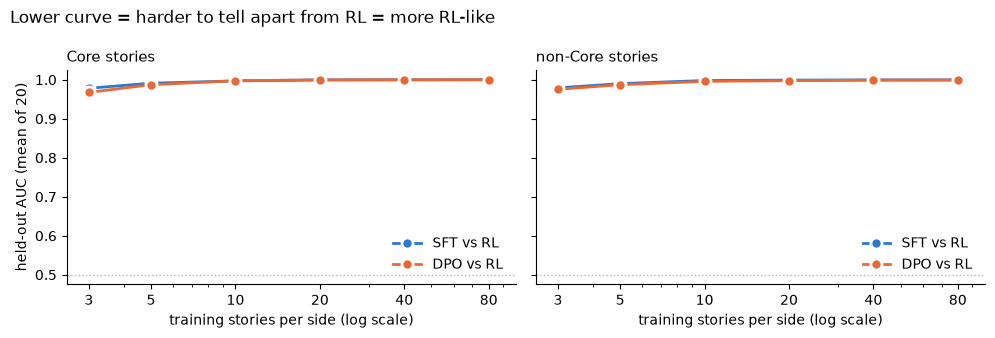

In [10]:
TRAIN_SIZES = [3, 5, 10, 20, 40, 80]
TEST_N = 60
LC_DRAWS = 20
rng = np.random.default_rng(SEED + 5)
lc_rows = []
for core in (True, False):
    label = "Core" if core else "non-Core"
    pools = {s: pool(s, core) for s in STAGES}
    for a in ("SFT", "DPO"):
        for k in TRAIN_SIZES:
            aucs = []
            for _ in range(LC_DRAWS):
                pa, pb = rng.permutation(pools[a]), rng.permutation(pools["RL"])
                X = np.concatenate([pa[:k], pb[:k]])
                Xt = np.concatenate([pa[k:k + TEST_N], pb[k:k + TEST_N]])
                m = make_model().set_params(tfidfvectorizer__min_df=1).fit(X, np.r_[np.zeros(k), np.ones(k)])
                aucs.append(roc_auc_score(np.r_[np.zeros(TEST_N), np.ones(TEST_N)], m.predict_proba(Xt)[:, 1]))
            lc_rows.append({"stories": label, "pair": f"{a} vs RL", "k": k, "auc": np.mean(aucs),
                            "lo": np.percentile(aucs, 2.5), "hi": np.percentile(aucs, 97.5)})
lc = pd.DataFrame(lc_rows)
display(lc.pivot_table(index="k", columns=["stories", "pair"], values="auc").round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, label in zip(axes, ("Core", "non-Core")):
    for a in ("SFT", "DPO"):
        g = lc[(lc["stories"] == label) & (lc["pair"] == f"{a} vs RL")]
        ax.plot(g["k"], g["auc"], "-o", color=COLORS[a], lw=2, ms=8, mec="white", mew=2, label=f"{a} vs RL")
    ax.set_xscale("log")
    ax.set_xticks(TRAIN_SIZES, TRAIN_SIZES)
    ax.set_xlim(2.5, 100)
    ax.legend(frameon=False, loc="lower right")
    ax.axhline(0.5, color="#b5b4ad", lw=1, ls=":")
    ax.set_title(f"{label} stories", loc="left", fontsize=11)
    ax.set_xlabel("training stories per side (log scale)")
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel(f"held-out AUC (mean of {LC_DRAWS})")
fig.suptitle("Lower curve = harder to tell apart from RL = more RL-like", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

## 7. How much do the controls matter? (ablation)

The Core-story projection, adding one control at a time. AUC is saturated at every step, so the useful
column is the **DPO position**: if it changes a lot when a control is added, the raw classifier's SFT → RL axis was
partly built on that shortcut. Fewer draws here (10) to keep it quick.

In [11]:
ABL_DRAWS = 10
plain = CountVectorizer(ngram_range=(1, 2), lowercase=True).build_analyzer()
variants = {
    "raw text, full length, no masking": ("raw", False, plain),
    "+ formatting normalized": ("norm", False, plain),
    f"+ first {N_WORDS} words only": ("trunc", True, plain),
    "+ names and Core words masked (main analysis)": ("text", True, analyzer),
}
abl = []
for name, (col, need_kept, an) in variants.items():
    sc = project("SFT", "RL", "DPO", True, draws=ABL_DRAWS, col=col, need_kept=need_kept,
                 model=lambda an=an: make_model(an), seed=SEED + 2)
    bt = boot_position(sc, "SFT", "RL", "DPO", reps=1000)
    abl.append({"variant": name, **{f"mean P(RL) | {s}": round(sc[s].mean(), 3) for s in STAGES},
                "DPO position": round(position(sc, "SFT", "RL", "DPO"), 3),
                "95% CI": f"[{np.percentile(bt, 2.5):.3f}, {np.percentile(bt, 97.5):.3f}]"})
pd.DataFrame(abl).set_index("variant")

,mean P(RL) | SFT,mean P(RL) | DPO,mean P(RL) | RL,DPO position,95% CI
variant,,,,,
"raw text, full length, no masking",0.257,0.312,0.737,0.115,"[0.092, 0.135]"
+ formatting normalized,0.257,0.312,0.737,0.115,"[0.092, 0.135]"
+ first 250 words only,0.277,0.332,0.723,0.124,"[0.102, 0.145]"
+ names and Core words masked (main analysis),0.277,0.333,0.723,0.125,"[0.103, 0.146]"


## 8. What differs? The n-grams the classifiers lean on

Fit each pairwise model once on a balanced Core sample and list the strongest weights. The "% of stories" columns
show the share of each stage's (kept) Core stories that contain the n-gram, so you can see whether DPO moved toward
RL on it.

In [12]:
def top_features(a: str, b: str, core: bool = True, k: int = 20, seed: int = SEED + 3):
    rng = np.random.default_rng(seed)
    pa, pb = pool(a, core), pool(b, core)
    n = min(len(pool("SFT", core)), len(pool("DPO", core)))
    X = np.concatenate([rng.choice(pa, n, replace=False), rng.choice(pb, n, replace=False)])
    y = np.r_[np.zeros(n), np.ones(n)]
    m = make_model().fit(X, y)
    vec, lr = m.named_steps["tfidfvectorizer"], m.named_steps["logisticregression"]
    names, w = vec.get_feature_names_out(), lr.coef_[0]
    pres = {s: CountVectorizer(analyzer=analyzer, vocabulary=names, binary=True)
                 .transform(pool(s, core)).mean(axis=0).A1 * 100 for s in STAGES}
    rows = []
    for side, idx in ((b, np.argsort(w)[::-1][:k]), (a, np.argsort(w)[:k])):
        for i in idx:
            rows.append({"marks": side, "n-gram": names[i], "weight": round(w[i], 2),
                         **{f"% {s}": round(pres[s][i], 1) for s in STAGES}})
    return pd.DataFrame(rows)


print("SFT vs RL, Core stories: n-grams that most mark each side")
display(top_features("SFT", "RL"))

SFT vs RL, Core stories: n-grams that most mark each side


,marks,n-gram,weight,% SFT,% DPO,% RL
0,RL,like,1.01,52.7,72.3,95.0
1,RL,storm,0.76,9.5,16.1,41.2
2,RL,into,0.75,46.4,51.7,79.7
3,RL,journal,0.72,2.3,2.2,32.7
4,RL,they,0.70,21.6,23.2,52.2
5,RL,rusted,0.59,2.3,3.7,30.0
6,RL,buried,0.59,1.8,1.9,26.0
7,RL,etched,0.59,2.3,1.5,28.1
8,RL,lay,0.58,4.1,7.5,34.6
9,RL,hissed,0.57,0.5,1.5,24.0


In [13]:
print("DPO vs RL, Core stories")
display(top_features("DPO", "RL"))
print("SFT vs DPO, Core stories")
display(top_features("SFT", "DPO"))

DPO vs RL, Core stories


,marks,n-gram,weight,% SFT,% DPO,% RL
0,RL,journal,0.84,2.3,2.2,32.7
1,RL,into,0.69,46.4,51.7,79.7
2,RL,buried,0.65,1.8,1.9,26.0
3,RL,rusted,0.65,2.3,3.7,30.0
4,RL,like,0.64,52.7,72.3,95.0
5,RL,storm,0.63,9.5,16.1,41.2
6,RL,jagged,0.62,3.6,4.5,27.4
7,RL,re,0.61,8.6,7.5,26.1
8,RL,hollow,0.61,1.4,3.7,26.6
9,RL,that night,0.59,6.3,3.7,34.4


SFT vs DPO, Core stories


,marks,n-gram,weight,% SFT,% DPO,% RL
0,DPO,battered,0.60,9.0,30.0,0.2
1,DPO,rain,0.60,30.6,58.4,14.1
2,DPO,like,0.58,52.7,72.3,95.0
3,DPO,xname end,0.57,0.9,12.4,0.3
4,DPO,something,0.52,26.1,43.1,25.8
5,DPO,fog,0.50,7.2,20.2,16.7
6,DPO,boots,0.49,14.9,33.7,21.2
7,DPO,memory,0.47,11.3,24.7,10.1
8,DPO,gray,0.46,4.1,17.6,7.8
9,DPO,against the,0.45,25.2,43.8,15.5


## 9. Sanity checks

- **Prompt mix:** SFT/DPO contain 5 prompts, RL one. Is SFT-vs-RL separability the same for every SFT prompt? If
  one prompt is far easier, the prompt (not the stage) drives part of the signal.
- **Masking worked:** no Core word or `xcore` n-gram may appear in any model's vocabulary.

In [14]:
rng = np.random.default_rng(SEED + 4)
rows = []
rl = pool("RL", True)
for prompt in df.loc[df["stage"] == "SFT", "prompt"].unique():
    row = {"prompt": prompt}
    for s in ("SFT", "DPO"):
        m = (df["stage"] == s) & df["core"] & df["kept"] & (df["prompt"] == prompt)
        pa = df.loc[m, "text"].to_numpy()
        n = min(len(pa), 30)
        aucs = [cv_auc(pa, rl, n, rng)[0] for _ in range(10)] if n >= 15 else []  # saturates too; mostly a leak check
        row[f"{s} Core stories"] = int(m.sum())
        row[f"{s} vs RL AUC (n={n})"] = summarize(aucs) if aucs else "too few"
    rows.append(row)
display(pd.DataFrame(rows).set_index("prompt"))

vocab = make_model().fit(np.concatenate([pool(s, True) for s in STAGES]),
                         np.r_[[0] * len(pool("SFT", True)), [1] * len(pool("DPO", True)), [1] * len(pool("RL", True))]
                         ).named_steps["tfidfvectorizer"].get_feature_names_out()
leaks = [g for g in vocab if "xcore" in g or PATTERN.search(g)]
print(f"vocabulary size {len(vocab):,}; Core words / xcore in vocabulary: {leaks[:10] or 'none'}")
names_left = [w for w in ("clara", "lila", "mira", "marrow", "willowbrook", "maya", "eleanor") if w in set(vocab)]
print("frequent story names still in vocabulary:", names_left or "none")

,SFT Core stories,SFT vs RL AUC (n=30),DPO Core stories,DPO vs RL AUC (n=30)
prompt,,,,
Write a story.,45,"1.000 [0.998, 1.000]",50,"1.000 [1.000, 1.000]"
Write me a story.,39,"1.000 [0.997, 1.000]",59,"1.000 [0.998, 1.000]"
Please write a story.,39,"0.999 [0.997, 1.000]",42,"0.999 [0.997, 1.000]"
Tell me a story.,55,"0.997 [0.983, 1.000]",63,"0.998 [0.991, 1.000]"
Please tell a story.,44,"0.995 [0.983, 1.000]",53,"1.000 [0.998, 1.000]"


vocabulary size 54,853; Core words / xcore in vocabulary: none
frequent story names still in vocabulary: ['marrow']


## 10. Interpretation

*(Written 2026-11-10 from the outputs above; re-check if the data, masking or settings change.)*

**Pipeline check: passes.** RL vs RL gives AUC ≈ 0.50 (Core and non-Core), so the cross-validation doesn't leak.
No Core word or `xcore` n-gram is in any vocabulary, and the frequent story names (*Clara, Lila, Willowbrook,
Marrow's End*) are masked.

**1. Pairwise AUC can't rank the stages: every Instruct story is trivially separable from the old Think run.**
SFT-vs-RL and DPO-vs-RL are both AUC ≈ 1.000, for Core and non-Core alike, for every prompt, and the learning curve
already reaches ≈ 0.97 with **3** training stories per side. The controls barely matter (§7). So the gap is not
length, markdown, names or Core words. It is pervasive word choice: RL Core stories are full of *journal, rusted,
etched, buried, attic, jagged, symbols, hissed* (25-35% of RL stories vs 1-4% of SFT/DPO), the "attic / old
journal / mysterious symbol" template. Instruct stories prefer *city, gentle, soft, quiet, "a young woman named X",
"she had"*. With only Instruct SFT/DPO vs the Think final, we **cannot** say whether this difference comes from the
Think branch (its SFT data are DeepSeek R1 traces) or from RL. That is the main limit of this notebook.

**2. Within that gap, DPO moves a little toward RL, and a bit more for Core stories.**
On the axis trained only on SFT vs RL, DPO sits at **0.126** of the way from SFT to RL for Core stories
(95% bootstrap CI 0.103-0.149), vs **0.080** (0.057-0.104) for non-Core. The Core-minus-non-Core difference is
**+0.046** (CI 0.014-0.079). It is small but holds under the bootstrap, and the position is stable across the
ablation (0.115-0.125). Only 0.4% of DPO stories would be classified as RL.

**3. SFT and DPO Core stories are clearly different from each other (AUC ≈ 0.87),** but no more different than
their non-Core stories (also 0.87). What DPO changed: more *rain, battered, fog, wind, boots, against the*, the
*Marrow's End* town, a weather-heavy coastal register. Less of SFT's fairy-tale opening, *"there lived a young woman
named X"* (*young woman* 20% → 0.7%, *named X* 46% → 17%). Some of this points toward RL (*like* 53 → 72 → 95%;
*storm* 10 → 16 → 41%; fewer *gentle/soft/she had*). Some points away from it (*rain* 31 → 58% vs RL 14%;
*battered* 9 → 30% vs RL 0.2%; *city*, *distant* stay far above RL).

**Answer to the question.** Yes, but only slightly. SFT's Core stories are somewhat *less* RL-like than DPO's
(DPO covers ~13% of the SFT → RL distance on Core stories, ~8% on non-Core). Almost all of the distance to the RL
Think model's stories is still there after DPO. On this evidence, the stories "start to look like RL's" mostly
**after DPO**, at the RL stage or in the Think branch, not at DPO.

**Caveats**
- **Branch/setup confound**: SFT and DPO are Instruct checkpoints with our 5-prompt setup; RL is the old Think run.
  Every "RL-like" claim is really "like the old Think-final run".
- **One sample** of 500 stories per checkpoint; the bootstrap covers story sampling but not seeds or settings.
- **Only the first 250 words** are compared, so endings and plot structure are ignored; TF-IDF sees word choice, not
  story shape.

**Next steps (in order of value)**
1. Generate ~500 **Think-final** stories with the Instruct setup (same 5 prompts, system prompt, sampling) and set
   `OLD_RL` to that file. This removes the run-setup part of the confound.
2. Generate stories from **Think-SFT and Think-DPO** GGUFs. Then all three stages share one branch, and a stage
   effect can be separated from a branch effect. If Think-SFT already shows *journal/attic/etched*, the template
   comes from SFT (R1 traces), not RL.
3. If AUC still saturates within one branch, use the projection and the learning curve as the main metrics.